In [ ]:
# Four frames plot
import numpy as np
import matplotlib.pyplot as plt

def plot_four_frames(
    cube,
    times=(0.05, 0.10, 0.15, 0.20),
    dt=0.001,
    dh=10.0,
    title="Respuesta al impulso directa",
    output_file=None,
):
    """
    cube: array con forma (nt, nz, nx).
    times: cuatro tiempos solicitados, en segundos.
    dt: intervalo temporal [s].
    dh: espaciamiento de la malla [m].
    """
    cube = np.asarray(cube)

    if cube.ndim != 3:
        raise ValueError("cube debe tener forma (nt, nz, nx).")
    if dt <= 0 or dh <= 0:
        raise ValueError("dt y dh deben ser positivos.")

    times = np.asarray(times, dtype=float)
    if times.shape != (4,) or not np.all(np.isfinite(times)):
        raise ValueError("Debes proporcionar cuatro tiempos finitos.")

    nt, nz, nx = cube.shape
    if np.any(times < 0) or np.any(times > (nt - 1) * dt):
        raise ValueError(
            f"Los tiempos deben estar entre 0 y {(nt - 1) * dt:.3f} s."
        )

    indices = np.rint(times / dt).astype(int)
    frames = cube[indices]

    # Escala simétrica compartida, ignorando NaN e infinitos.
    finite_values = frames[np.isfinite(frames)]
    if finite_values.size == 0:
        raise ValueError("Los frames seleccionados no tienen valores finitos.")

    vmax = np.max(np.abs(finite_values))
    if vmax == 0:
        vmax = 1.0

    cmap = plt.get_cmap("seismic").copy()
    cmap.set_bad("lightgray")

    # Los centros de los píxeles coinciden con x=i*dh, z=j*dh.
    extent = (
        -dh / 2,
        (nx - 0.5) * dh,
        (nz - 0.5) * dh,
        -dh / 2,
    )

    fig, axes = plt.subplots(
        2, 2,
        figsize=(10, 9),
        sharex=True,
        sharey=True,
        layout="constrained",
    )

    for ax, index, frame in zip(axes.flat, indices, frames):
        im = ax.imshow(
            np.ma.masked_invalid(frame),
            cmap=cmap,
            vmin=-vmax,
            vmax=vmax,
            origin="upper",
            extent=extent,
            aspect="equal",
            interpolation="nearest",
        )
        ax.set_title(f"t = {index * dt:.3f} s")
        ax.set_xlabel("x [m]")
        ax.set_ylabel("Profundidad [m]")

    fig.suptitle(title)
    fig.colorbar(
        im,
        ax=axes.ravel().tolist(),
        label="Amplitud",
        shrink=0.85,
        pad=0.03,
    )

    if output_file is not None:
        fig.savefig(output_file, dpi=300, bbox_inches="tight")

    plt.show()
    return fig, axes

In [ ]:
import numpy as np
from pathlib import Path
from numpy.polynomial.legendre import leggauss

# ============================================================
# 1. Parámetros
# ============================================================
velocities = np.array(
    [1500, 2000, 2500, 3000, 3500, 4000, 4500],
    dtype=float,
)

nx = 70
nz = 70
nt = 800

dh = 10.0       # [m]
dt = 0.001      # [s]
f0 = 15.0      # [Hz]
t0 = 1.5 / f0 # 0.1 equivalente
amplitude = 1.0

x = np.arange(nx) * dh
z = np.arange(nz) * dh
t = np.arange(nt) * dt

# Fuente en una de las dos columnas centrales y a 300 m.
ix_source = nx // 2
iz_source = nz // 2

x_source = x[ix_source]
z_source = z[iz_source]

# Misma normalización del código anterior:
# P_new[ix_source, iz_source] += src[it_new]
source_scale = dh**2 / dt**2

n_quad = 96
nodes, weights = leggauss(n_quad)

output_path = Path(
    "../../data/wavefields/analytical/wavefield_59.npy"
)
output_path.parent.mkdir(parents=True, exist_ok=True)

# ============================================================
# 2. Ricker causal
# ============================================================
def ricker(time):
    time = np.asarray(time)
    a = (np.pi * f0 * (time - t0))**2
    wavelet = amplitude * (1.0 - 2.0 * a) * np.exp(-a)
    return np.where(time >= 0.0, wavelet, 0.0)

# ============================================================
# 3. Distancias directa e imagen
# ============================================================
# Trabajamos en unidades de píxel para identificar exactamente
# las distancias repetidas.
IZ, IX = np.indices((nz, nx))

distance_squared_direct = (
    (IX - ix_source)**2 + (IZ - iz_source)**2
)
distance_squared_image = (
    (IX - ix_source)**2 + (IZ + iz_source)**2
)

# Una tabla común para ambas contribuciones.
unique_squared, inverse = np.unique(
    np.concatenate([
        distance_squared_direct.ravel(),
        distance_squared_image.ravel(),
    ]),
    return_inverse=True,
)

n_pixels = nz * nx

index_direct = inverse[:n_pixels].reshape(nz, nx)
index_image = inverse[n_pixels:].reshape(nz, nx)

distances = dh * np.sqrt(unique_squared.astype(float))

# ============================================================
# 4. Respuesta puntual 2D por distancia
# ============================================================
def response_by_distance(distances, times, c):
    """
    Devuelve un array (Nt, número de distancias).

    Integra la función de Green 2D mediante:
        v = (r/c) * cosh(u)

    La sustitución elimina la singularidad integrable
    del frente de onda para r > 0.
    """
    travel = distances / c

    response = np.zeros(
        (len(times), len(distances)),
        dtype=np.float64,
    )

    # La fuente puntual continua es singular en r = 0.
    singular = (distances == 0.0)
    response[:, singular] = np.nan

    prefactor = source_scale / (2.0 * np.pi * c**2)

    for it, time in enumerate(times):
        active = (travel > 0.0) & (time > travel)

        if not np.any(active):
            continue

        a = travel[active]
        u_max = np.arccosh(time / a)

        u = (
            0.5 * u_max[:, None]
            * (nodes[None, :] + 1.0)
        )

        emission_time = time - a[:, None] * np.cosh(u)

        integral = (
            0.5 * u_max
            * np.sum(
                ricker(emission_time) * weights[None, :],
                axis=1,
            )
        )

        response[it, active] = prefactor * integral

    return response

# ============================================================
# 5. Crear el archivo y calcular los siete cubos
# ============================================================
# Memmap escribe directamente en un archivo .npy válido.
# float32: aproximadamente 110 MB para el cubo completo.
shape = (len(velocities), nt, nz, nx)

wavefields = np.lib.format.open_memmap(
    output_path,
    mode="w+",
    dtype=np.float32,
    shape=shape,
)

for imodel, c in enumerate(velocities):
    print(
        f"Calculando modelo {imodel + 1}/{len(velocities)}: "
        f"c = {c:g} m/s",
        flush=True,
    )

    response = response_by_distance(distances, t, c)

    # Reconstrucción del campo:
    # (Nt, Nz, Nx), directa menos fuente imagen.
    field = (
        response[:, index_direct]
        - response[:, index_image]
    )

    # Verificar la condición de superficie libre.
    surface_error = np.max(np.abs(field[:, 0, :]))
    assert surface_error == 0.0
    
    max_amplitude = np.nanmax(field)

    # Únicamente el nodo de la fuente debe contener NaN.
    assert np.count_nonzero(np.isnan(field)) == nt

    wavefields[imodel] = field.astype(np.float32)
    wavefields.flush()

    print(
        f"  Guardado: {field.shape}; "
        f"máximo |p| en superficie = {surface_error:.3e}",
        f"maxima amplitud = {max_amplitude:.3e}" ,
        flush=True,
    )

    del response, field

# Cerrar el acceso de escritura.
del wavefields

# ============================================================
# 6. Verificar el archivo guardado
# ============================================================
saved = np.load(output_path, mmap_mode="r")

assert saved.shape == (7, 800, 70, 70)
assert saved.dtype == np.float32

print(f"\nArchivo: {output_path}")
print(f"Forma: {saved.shape}")
print(f"Tipo: {saved.dtype}")
print(f"Tiempo: {t[0]:.3f} a {t[-1]:.3f} s")
print(f"Fuente: x={x_source:g} m, z={z_source:g} m")
print(f"Tamaño: {output_path.stat().st_size / 1e6:.1f} MB")

Calculando modelo 1/7: c = 1500 m/s
  Guardado: (800, 70, 70); máximo |p| en superficie = 0.000e+00 maxima amplitud = 1.028e+01
Calculando modelo 2/7: c = 2000 m/s
  Guardado: (800, 70, 70); máximo |p| en superficie = 0.000e+00 maxima amplitud = 6.514e+00
Calculando modelo 3/7: c = 2500 m/s
  Guardado: (800, 70, 70); máximo |p| en superficie = 0.000e+00 maxima amplitud = 4.561e+00
Calculando modelo 4/7: c = 3000 m/s
  Guardado: (800, 70, 70); máximo |p| en superficie = 0.000e+00 maxima amplitud = 3.396e+00
Calculando modelo 5/7: c = 3500 m/s
  Guardado: (800, 70, 70); máximo |p| en superficie = 0.000e+00 maxima amplitud = 2.644e+00
Calculando modelo 6/7: c = 4000 m/s
  Guardado: (800, 70, 70); máximo |p| en superficie = 0.000e+00 maxima amplitud = 2.125e+00
Calculando modelo 7/7: c = 4500 m/s
  Guardado: (800, 70, 70); máximo |p| en superficie = 0.000e+00 maxima amplitud = 1.751e+00

Archivo: ../../data/wavefields/analytical/wavefield_59.npy
Forma: (7, 800, 70, 70)
Tipo: float32
Tiempo

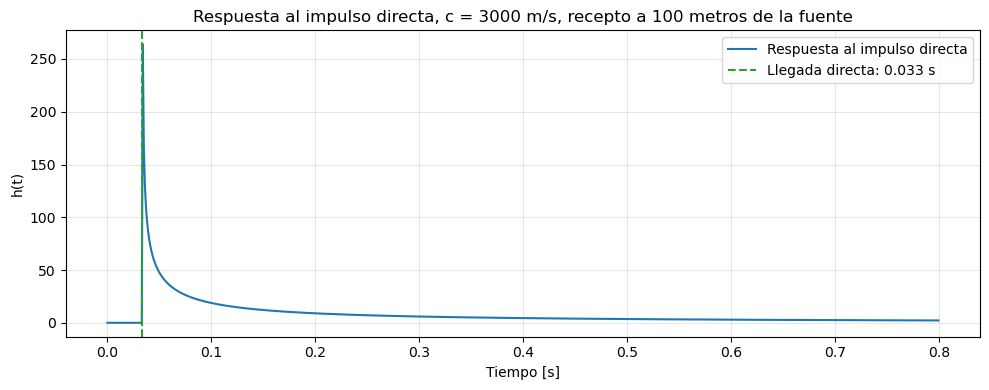

In [13]:
import numpy as np
import matplotlib.pyplot as plt

imodel = 3
c = velocities[imodel]

ix_receiver = 45
iz_receiver = 35

xr = x[ix_receiver]
zr = z[iz_receiver]

r_direct = np.hypot(xr - x_source, zr - z_source)

def green_2d(r, times, c):
    if r <= 0:
        raise ValueError("El receptor debe estar fuera de la fuente.")

    arrival = r / c
    g = np.zeros_like(times, dtype=float)

    # El frente exacto es singular.
    at_front = np.isclose(times, arrival, rtol=0.0, atol=1e-12)
    after_front = (times > arrival) & ~at_front

    g[after_front] = 1.0 / (
        2.0 * np.pi * c**2
        * np.sqrt(times[after_front]**2 - arrival**2)
    )
    g[at_front] = np.nan

    return g

# Solo contribución directa, con la escala del código original.
h = source_scale * green_2d(r_direct, t, c)

fig, ax = plt.subplots(figsize=(10, 4))

ax.plot(t, h, label="Respuesta al impulso directa")
ax.axvline(
    r_direct / c,
    color="tab:green",
    linestyle="--",
    label=f"Llegada directa: {r_direct / c:.3f} s",
)

ax.set_xlabel("Tiempo [s]")
ax.set_ylabel("h(t)")
ax.set_title(f"Respuesta al impulso directa, c = {c:g} m/s, recepto a {(ix_receiver - 35)*10} metros de la fuente")
ax.grid(alpha=0.3)
ax.legend()

plt.tight_layout()
plt.show()

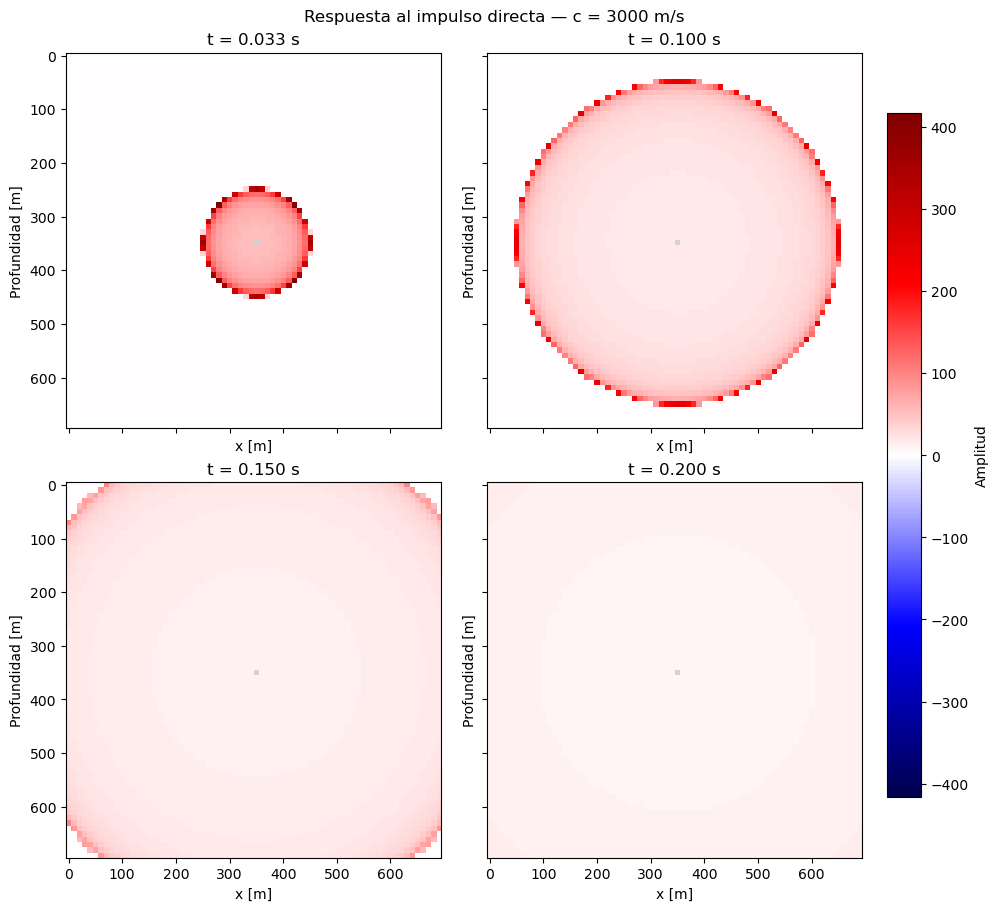

In [15]:
import numpy as np

# ------------------------------------------------------------
# 1. Modelo y distancias a la fuente
# ------------------------------------------------------------
imodel = 3
c = float(velocities[imodel])

vel_model = np.full((nz, nx), c)

IZ, IX = np.indices((nz, nx))
r = dh * np.hypot(IX - ix_source, IZ - iz_source)

outside_source = r > 0.0
arrival = r[outside_source] / c

# ------------------------------------------------------------
# 2. Respuesta al impulso directa
#    Promedio temporal de la función de Green en cada intervalo
# ------------------------------------------------------------
impulse_cube = np.zeros((nt, nz, nx), dtype=np.float64)

prefactor = source_scale / (2.0 * np.pi * c**2)

for it, time in enumerate(t):
    # Integral de 1 / sqrt(s**2 - arrival**2):
    # arccosh(s / arrival), para s > arrival.
    integral_start = np.arccosh(
        np.maximum(time / arrival, 1.0)
    )
    integral_end = np.arccosh(
        np.maximum((time + dt) / arrival, 1.0)
    )

    impulse_cube[it, outside_source] = (
        prefactor * (integral_end - integral_start) / dt
    )

# La fuente puntual sigue siendo singular espacialmente.
impulse_cube[:, iz_source, ix_source] = np.nan

# ------------------------------------------------------------
# 3. Frames que se quieren visualizar
# ------------------------------------------------------------
time_1 = int(round(0.10 / dt))
time_2 = int(round(0.20 / dt))

# Evita la profundidad de la fuente para las trazas,
# porque tu función no maneja NaN al normalizarlas.
z_receiver = 20

# Tu función requiere dos cubos.
# Repetimos el mismo únicamente para visualizarlo:
# NO representa una solución por diferencias finitas.
fig, axes = plot_four_frames(
    cube=impulse_cube,
    times=(0.033, 0.10, 0.15, 0.20),
    dt=dt,
    dh=dh,
    title=f"Respuesta al impulso directa — c = {c:g} m/s",
    # output_file="impulse_four_frames.pdf",
)